# 02 · Tree models (E2–E5)

Same protocol as notebook 01: 3 folds, validated on proxy (forecast) weather, Uri hours not scored.
The floor to beat is `same_hour_latest`: **8.18% MAPE, 6.50% Peak-MAPE**.

| # | Question |
|---|---|
| E2 | Which tree model, and which target form: raw MW, trend + residual (v1), or ratio to the last week's mean load? |
| E3 | Train on ERA5-as-forecast (2016+), on archived forecasts (2021+), or on a hybrid of the two? |
| E4 | Uri: exclude, down-weight to 0.1, or keep? |
| E5 | Do forecast humidity and precipitation help? (fold 3 only, where the forecasts exist) |

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
from shef.models import cv, data, gbdt, plots, report, tracking

FLOOR_PEAK = 6.50  # same_hour_latest, notebook 01
mlflow = tracking.init()
features = data.default_features()
tables = data.load_tables(features + data.LATE_FORECAST_VARS)
len(features), {k: v.shape for k, v in tables.items()}

(42, {'obs': (94175, 47), 'proxy': (48576, 47)})

## E2 · Model × target form

  E2_lgbm_raw                  fold 1: MAPE 4.90%  peak 4.15%  (train 57,190 / val 8,760)


  E2_lgbm_raw                  fold 2: MAPE 5.88%  peak 5.08%  (train 65,950 / val 8,784)


  E2_lgbm_raw                  fold 3: MAPE 4.49%  peak 3.80%  (train 74,734 / val 8,760)


🏃 View run E2_lgbm_raw at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3/runs/7033612ca83b409486114e13d84876a4
🧪 View experiment at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3


  E2_lgbm_trend                fold 1: MAPE 4.04%  peak 3.05%  (train 57,190 / val 8,760)


...

  E2_catboost_ratio            fold 1: MAPE 5.01%  peak 3.81%  (train 57,190 / val 8,760)


  E2_catboost_ratio            fold 2: MAPE 6.46%  peak 4.38%  (train 65,950 / val 8,784)


  E2_catboost_ratio            fold 3: MAPE 4.29%  peak 4.21%  (train 74,734 / val 8,760)


🏃 View run E2_catboost_ratio at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3/runs/239ad5dbbc714309aeafd42bd409f52e
🧪 View experiment at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3


,mape,peak_mape,rmse,bias_pct,fold1_mape,fold2_mape,fold3_mape,minutes,passes_peak_rule
E2_catboost_trend,4.84,3.75,674.79,1.01,4.15,6.31,4.06,3.16,True
E2_lgbm_trend,4.85,3.64,674.35,1.28,4.04,6.33,4.19,1.25,True
E2_catboost_raw,5.00,4.48,652.67,-1.14,5.21,5.56,4.24,2.75,True
E2_xgb_trend,5.02,3.33,728.08,0.87,4.38,6.58,4.11,0.72,True
E2_lgbm_raw,5.09,4.34,673.42,-0.74,4.90,5.88,4.49,1.08,True
E2_catboost_ratio,5.26,4.13,726.05,-0.39,5.01,6.46,4.29,2.33,True
E2_xgb_ratio,5.28,4.59,674.29,-0.56,5.39,5.85,4.59,0.74,True
E2_xgb_raw,5.29,4.31,692.98,-1.07,5.39,5.94,4.54,0.86,True
E2_lgbm_ratio,5.36,4.48,685.07,-0.48,5.63,6.02,4.43,0.78,True


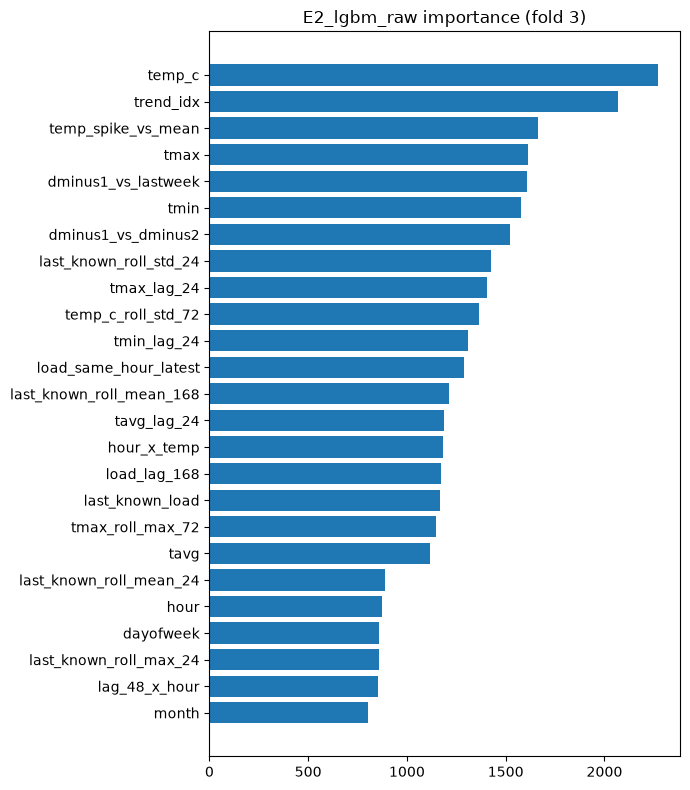

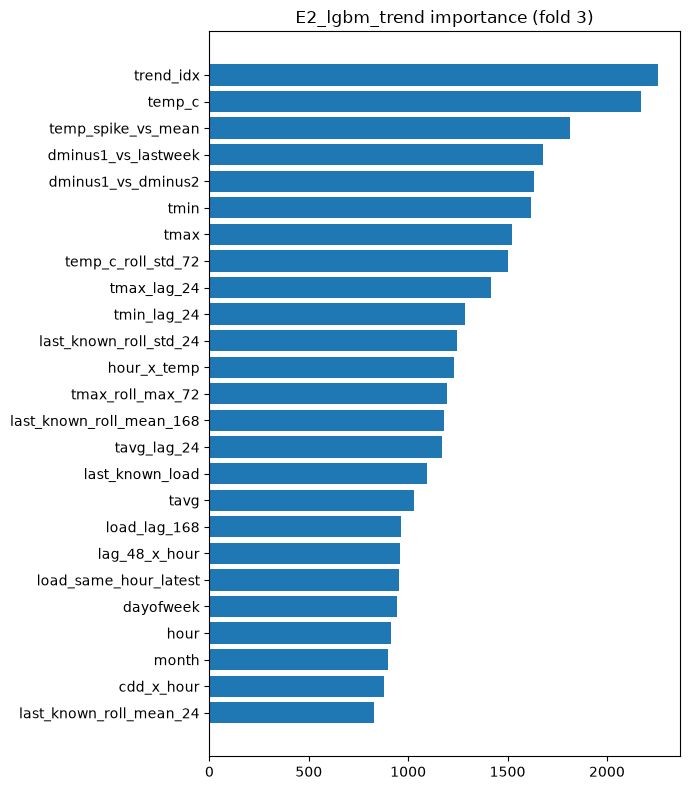

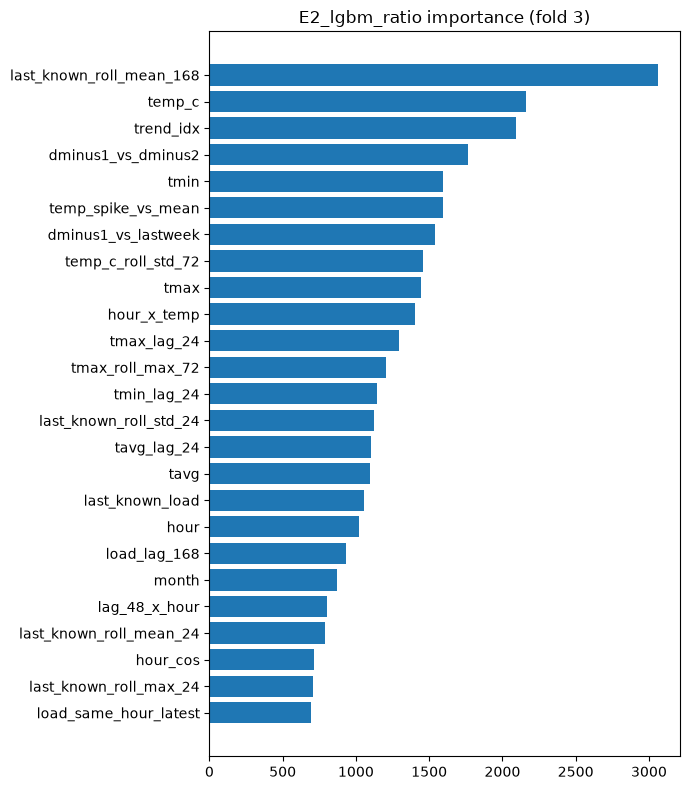

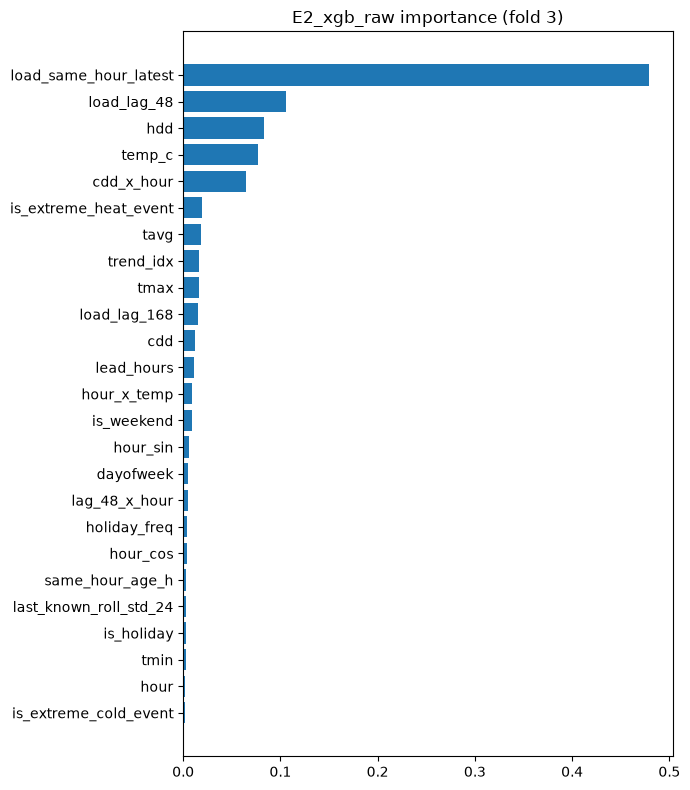

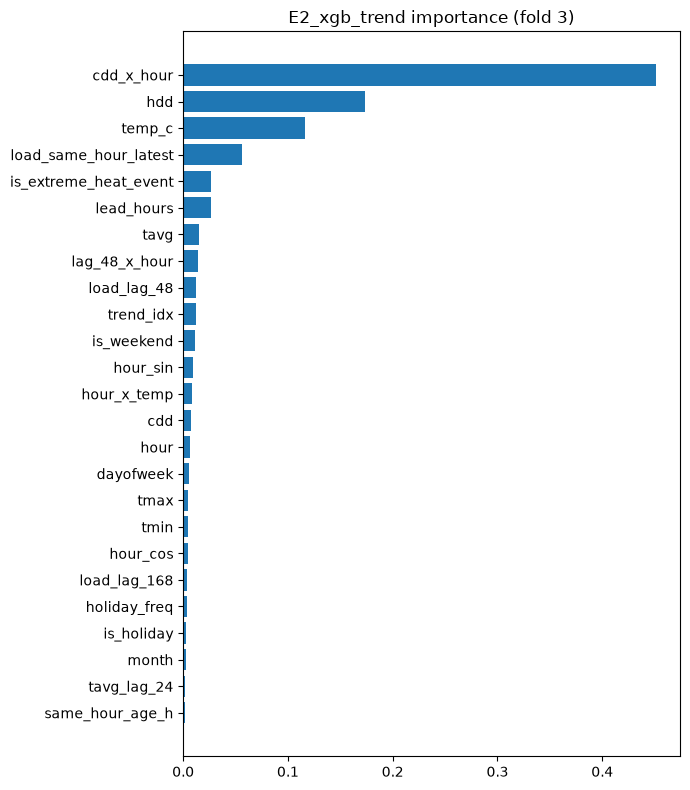

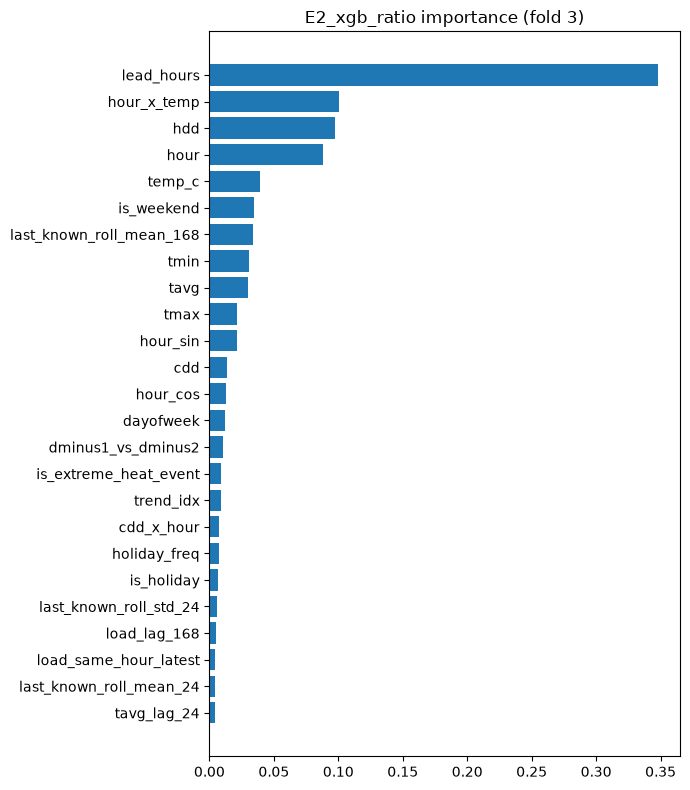

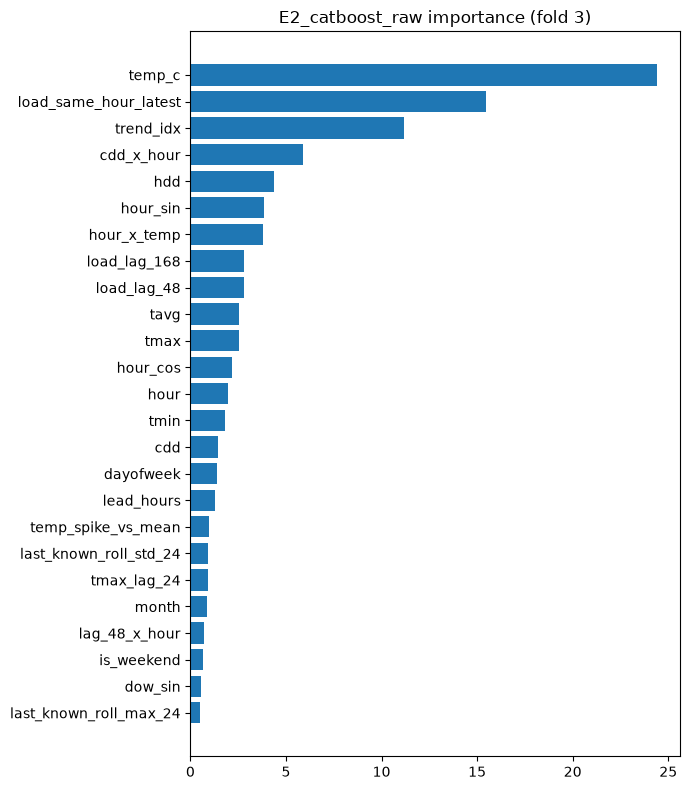

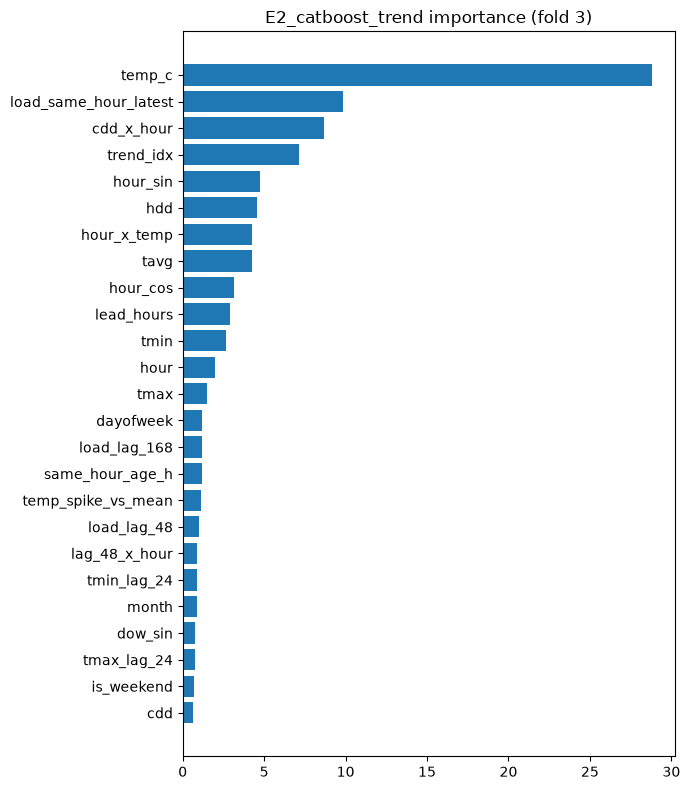

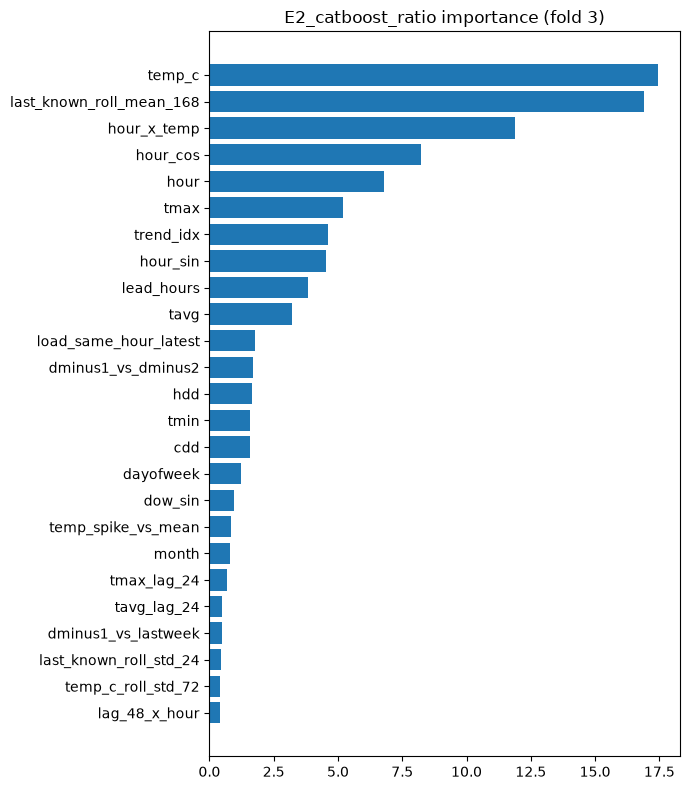

In [2]:
MODELS = {"lgbm": gbdt.lgbm, "xgb": gbdt.xgb, "catboost": gbdt.catboost}
TARGETS = ["raw", "trend", "ratio"]
e2 = {}
for m, build in MODELS.items():
    for t in TARGETS:
        spec = cv.Spec(f"E2_{m}_{t}", lambda b=build: b(), target=t)
        e2[spec.name] = r = cv.run_cv(spec, tables)
        imp = getattr(r.models[3][0], "feature_importances_", None)
        figs = {"importance": plots.importance(spec.features, imp, title=f"{spec.name} importance (fold 3)")} if imp is not None else {}
        report.log_result(r, figures=figs, tags={"experiment": "E2"})
t2 = report.results_table(e2)
t2["passes_peak_rule"] = t2["peak_mape"] <= FLOOR_PEAK
t2

E2 best: E2_catboost_trend


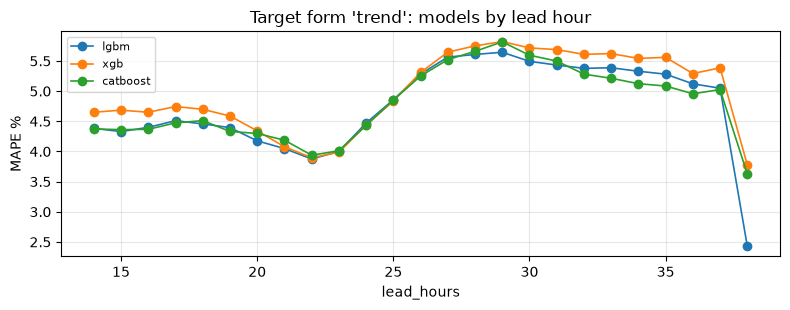

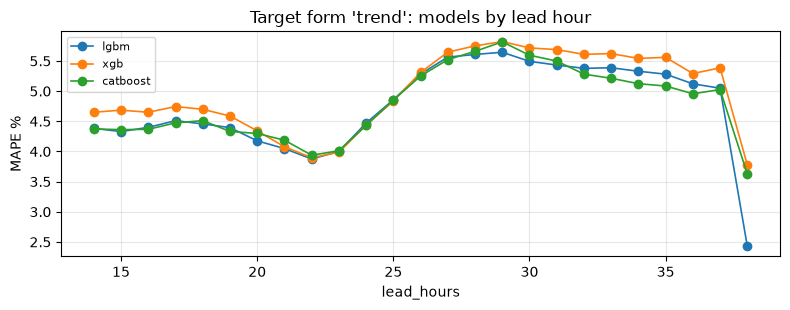

In [3]:
best2 = report.champion(t2, FLOOR_PEAK)
best_model, best_target = best2.split("_")[1], best2.split("_")[2]
print("E2 best:", best2)
leads = e2[best2].scored.copy()
for m in MODELS:
    leads[m] = e2[f"E2_{m}_{best_target}"].scored["pred"].to_numpy()
plots.compare_by(leads, "lead_hours", list(MODELS), f"Target form '{best_target}': models by lead hour")

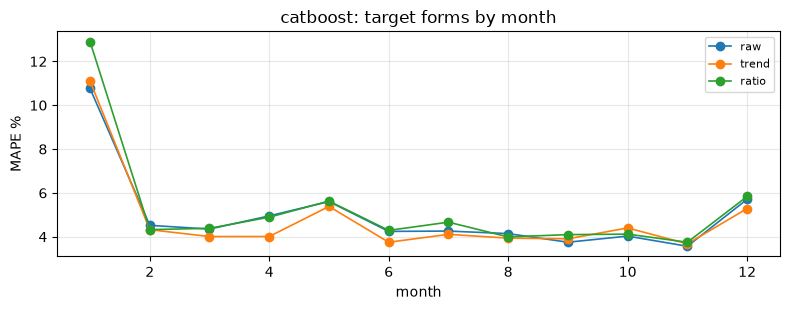

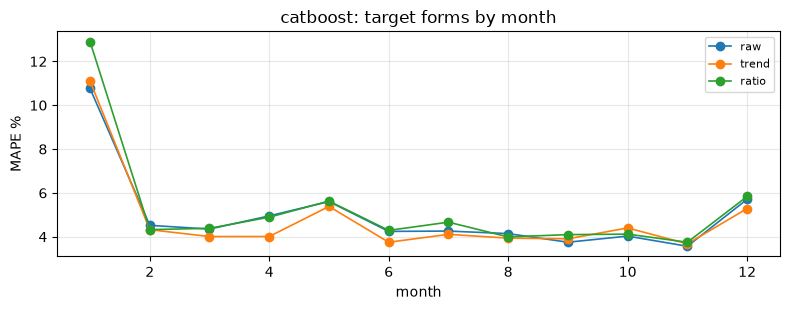

In [4]:
cmp = e2[best2].scored.copy()
for t in TARGETS:
    cmp[t] = e2[f"E2_{best_model}_{t}"].scored["pred"].to_numpy()
plots.compare_by(cmp, "month", TARGETS, f"{best_model}: target forms by month")

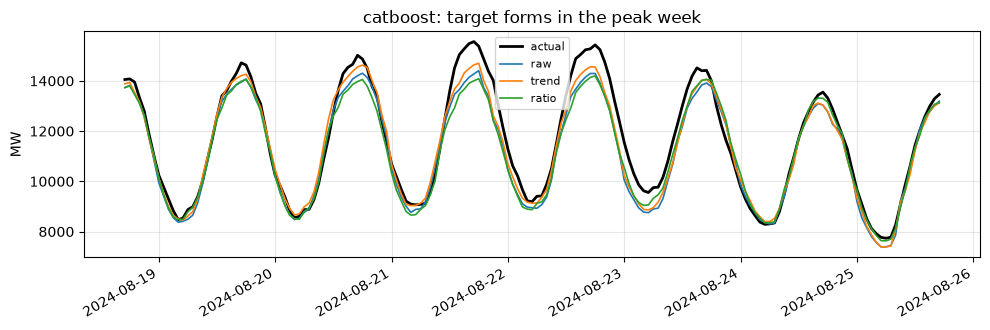

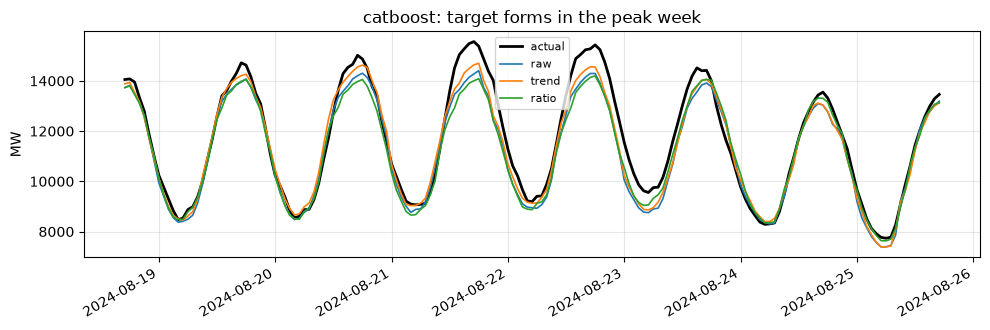

In [5]:
plots.peak_week(cmp, TARGETS, f"{best_model}: target forms in the peak week")

## E3 · Training weather source

In [6]:
e3 = {f"E3_{best2}_obs": e2[best2]}
for src in ["proxy", "hybrid"]:
    spec = cv.Spec(f"E3_{best2}_{src}", lambda: gbdt.BUILDERS[best_model](), target=best_target, train_source=src)
    e3[spec.name] = r = cv.run_cv(spec, tables)
    report.log_result(r, tags={"experiment": "E3"})
t3 = report.results_table(e3)
t3

  E3_E2_catboost_trend_proxy   fold 1: MAPE 11.23%  peak 4.94%  (train 11,856 / val 8,760)


  E3_E2_catboost_trend_proxy   fold 2: MAPE 9.48%  peak 4.36%  (train 20,616 / val 8,784)


  E3_E2_catboost_trend_proxy   fold 3: MAPE 4.74%  peak 4.93%  (train 29,400 / val 8,760)


🏃 View run E3_E2_catboost_trend_proxy at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3/runs/4e16164096224b3089396e131726c1b9
🧪 View experiment at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3


  E3_E2_catboost_trend_hybrid  fold 1: MAPE 3.87%  peak 3.56%  (train 57,137 / val 8,760)


  E3_E2_catboost_trend_hybrid  fold 2: MAPE 6.35%  peak 5.15%  (train 65,897 / val 8,784)


  E3_E2_catboost_trend_hybrid  fold 3: MAPE 4.04%  peak 5.34%  (train 74,681 / val 8,760)


🏃 View run E3_E2_catboost_trend_hybrid at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3/runs/40d5249e3a7b4b4280b3c0e51e590ab3
🧪 View experiment at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3


,mape,peak_mape,rmse,bias_pct,fold1_mape,fold2_mape,fold3_mape,minutes
E3_E2_catboost_trend_hybrid,4.76,4.68,684.31,0.61,3.87,6.35,4.04,2.25
E3_E2_catboost_trend_obs,4.84,3.75,674.79,1.01,4.15,6.31,4.06,3.16
E3_E2_catboost_trend_proxy,8.48,4.74,904.57,5.99,11.23,9.48,4.74,1.56


In [7]:
best3 = report.champion(t3, FLOOR_PEAK)
best_source = best3.rsplit("_", 1)[1]
print("E3 best training source:", best_source)

E3 best training source: hybrid


## E4 · Uri (Feb 2021) in training

In [8]:
e4 = {f"E4_exclude": e3[best3]}
for uri in ["weight", "keep"]:
    spec = cv.Spec(f"E4_{best_model}_{best_target}_{best_source}_uri_{uri}", lambda: gbdt.BUILDERS[best_model](),
                   target=best_target, train_source=best_source, uri=uri)
    e4[f"E4_{uri}"] = r = cv.run_cv(spec, tables)
    report.log_result(r, tags={"experiment": "E4"})
t4 = report.results_table(e4)
t4

  E4_catboost_trend_hybrid_uri_weight fold 1: MAPE 3.83%  peak 4.07%  (train 57,401 / val 8,760)


  E4_catboost_trend_hybrid_uri_weight fold 2: MAPE 6.47%  peak 5.35%  (train 66,161 / val 8,784)


  E4_catboost_trend_hybrid_uri_weight fold 3: MAPE 4.12%  peak 4.65%  (train 74,945 / val 8,760)


🏃 View run E4_catboost_trend_hybrid_uri_weight at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3/runs/f7e7f7703ad1499993da2c9233899888
🧪 View experiment at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3


  E4_catboost_trend_hybrid_uri_keep fold 1: MAPE 3.88%  peak 3.75%  (train 57,401 / val 8,760)


  E4_catboost_trend_hybrid_uri_keep fold 2: MAPE 6.35%  peak 5.33%  (train 66,161 / val 8,784)


  E4_catboost_trend_hybrid_uri_keep fold 3: MAPE 4.16%  peak 5.66%  (train 74,945 / val 8,760)


🏃 View run E4_catboost_trend_hybrid_uri_keep at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3/runs/9c02491a36a74b2e86cb830493363768
🧪 View experiment at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3


,mape,peak_mape,rmse,bias_pct,fold1_mape,fold2_mape,fold3_mape,minutes
E4_exclude,4.76,4.68,684.31,0.61,3.87,6.35,4.04,2.25
E4_keep,4.80,4.91,687.77,0.76,3.88,6.35,4.16,3.17
E4_weight,4.81,4.69,703.53,0.76,3.83,6.47,4.12,2.83


In [9]:
best_uri = report.champion(t4, FLOOR_PEAK).split("_")[1]
print("E4 Uri handling:", best_uri)

E4 Uri handling: exclude


## E5 · Forecast humidity and precipitation (fold 3 only)

Archived forecasts for these two only start in January 2024, so only fold 3 (Aug 2024 → Aug 2025) can test them honestly.

In [10]:
e5 = {}
for label, feats in {"without": features, "with": features + data.LATE_FORECAST_VARS}.items():
    spec = cv.Spec(f"E5_{best_model}_{best_target}_{label}_hum_precip", lambda: gbdt.BUILDERS[best_model](),
                   target=best_target, features=feats, train_source=best_source, uri=best_uri, fold_ids=(3,))
    e5[label] = r = cv.run_cv(spec, tables)
    report.log_result(r, tags={"experiment": "E5"})
report.results_table(e5)

  E5_catboost_trend_without_hum_precip fold 3: MAPE 4.04%  peak 5.34%  (train 74,681 / val 8,760)


🏃 View run E5_catboost_trend_without_hum_precip at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3/runs/1a43cd5388d04a17916d963ea4d57b1d
🧪 View experiment at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3


  E5_catboost_trend_with_hum_precip fold 3: MAPE 4.04%  peak 5.51%  (train 74,681 / val 8,760)


🏃 View run E5_catboost_trend_with_hum_precip at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3/runs/ddbc2f81553b4109a82cd731541ad097
🧪 View experiment at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3


,mape,peak_mape,rmse,bias_pct,fold3_mape,minutes
without,4.04,5.34,508.67,-0.73,4.04,0.76
with,4.04,5.51,508.93,-0.75,4.04,1.04


## Carried forward

In [11]:
carry = {"model": best_model, "target": best_target, "train_source": best_source, "uri": best_uri,
         "humidity_precip": e5["with"].metrics["mape"] < e5["without"].metrics["mape"] - 0.05}
carry

{'model': 'catboost',
 'target': 'trend',
 'train_source': 'hybrid',
 'uri': 'exclude',
 'humidity_precip': False}

## Reading

**E2: the trend + residual target wins for all three models.** CatBoost scores 4.84%, LightGBM 4.85% and XGBoost 5.02% MAPE, against 8.18% for the floor.
- The ratio target came last for every model. v1's trend decomposition holds up.
- CatBoost and LightGBM are a tie (0.01 points apart). LightGBM trains 2.5× faster.
- XGBoost + trend has the best Peak-MAPE (3.33%), which makes it a good ensemble member (E7).
- Trend targets over-forecast slightly (bias +0.9 to +1.3%); raw targets under-forecast (−0.7 to −1.1%).

**E3: the automatic rule picked `hybrid` training weather, and I'm overriding it in favour of `obs`.**
- Hybrid gains 0.08 points of MAPE (4.76 vs 4.84) but loses 0.93 points of Peak-MAPE (4.68 vs 3.75).
- The P3 rule only required Peak-MAPE to beat the floor, so it couldn't see that trade.
- From here on, MAPE differences under 0.1 points count as a tie, and a tie goes to the better Peak-MAPE.
- Training on archived forecasts only (2021+) is much worse: 8.48% MAPE, a +6% bias, and 11.2% on fold 1, where it has only about 1.4 years of history.

**E4: Uri handling barely matters.** Exclude, weight 0.1 and keep are all within 0.05 points. Exclude stays.

**E5: forecast humidity and precipitation add nothing.** Fold 3 MAPE is 4.04% either way, and Peak-MAPE is slightly worse with them (5.51 vs 5.34). They're dropped from the feature set.

**Fold 2 (Aug 2023 → Aug 2024) is the hard year:** about 6.3% MAPE for every model, against roughly 4% in folds 1 and 3. That window includes summer 2023's record Texas heat. E9 (SHAP) should look at what the models miss there.

**Carried forward:** trend target, `obs` training weather, Uri excluded, default features (no humidity or precipitation). The model candidates are CatBoost, LightGBM and XGBoost, all with the trend target, for E7–E8.